# Deteksi Kerusakan Jalan · YOLO di VS Code / WSL2 (GTX 1080 Ti)

**Versi perbaikan instalasi:** memakai PyTorch **2.6.0 + CUDA 11.8** karena NVIDIA GTX 1080 Ti berarsitektur Pascal (sm_61), bukan versi `cu128` yang tidak lagi menyertakan dukungan Pascal pada build CUDA 12.8 terbaru.

### Sekali saja — siapkan environment khusus YOLO (terminal Ubuntu WSL2)

Jangan jalankan ini di virtual environment `.venv-tf` milik TensorFlow skripsi. Buka Ubuntu, lalu:

```bash
mkdir -p ~/deteksi-jalan
cd ~/deteksi-jalan
python3.10 -m venv .venv-yolo
source .venv-yolo/bin/activate
python -m pip install --upgrade pip ipykernel
python -m ipykernel install --user --name jalan-gpu --display-name "Python (YOLO GTX 1080 Ti)"
code .
```

Taruh notebook ini dalam folder `~/deteksi-jalan`, buka pada VS Code **WSL: Ubuntu**, lalu pilih kernel **Python (YOLO GTX 1080 Ti)**. Jika instalasi virtual environment gagal, pastikan paket sistem `python3.10-venv` tersedia. Gunakan Python 3.10 yang sudah dipasang di WSL.

### Cara menjalankan

1. **Sel 0:** instal dependensi (sekali saja, tunggu selesai). Unduhannya masih besar; `pip` disetel punya lebih banyak waktu dan percobaan resume. Restart kernel sekali setelah berhasil.
2. **Sel 1:** setup setiap kali buka notebook.
3. **Bagian A:** menyiapkan dataset (cukup sekali).
4. **Bagian C:** training YOLO.
5. **Bagian D:** evaluasi.

**Catatan:** keberhasilan instalasi tidak ditentukan dari status `torch.cuda.is_available()` saja; Sel 0 menguji komputasi langsung di CUDA. Cek ruang disk yang tersedia dengan `df -h` (disarankan sedikitnya 8 GB kosong untuk dependensi dan file sementara, di luar dataset).

**Struktur output:** direktori `data/`, `runs/`, `models/`, `eval/`, dan `hasil_evaluasi.csv` akan dibuat di folder project saat dieksekusi.


In [ ]:
# Sel 0 · Instalasi pustaka untuk WSL2 GTX 1080 Ti (sekali saja, lalu Restart Kernel)
# Memilih CUDA 11.8 + PyTorch 2.6.0 agar dukungan Pascal (sm_61) tetap tersedia.
import os, sys, subprocess
from pathlib import Path

# JANGAN menimpa environment TensorFlow skripsi.
env_path = str(Path(sys.prefix).resolve())
if ".venv-tf" in env_path:
    raise RuntimeError(
        "Kernel masih menggunakan .venv-tf (TensorFlow skripsi). "
        "Buat .venv-yolo sesuai petunjuk di sel paling atas dan pilih kernel 'Python (YOLO GTX 1080 Ti)' terlebih dahulu."
    )

if sys.prefix == sys.base_prefix:
    raise RuntimeError("Kamu belum memilih virtual environment. Gunakan kernel Python (YOLO GTX 1080 Ti), bukan system Python.")

# Test dengan operasi CUDA nyata, sebab torch.cuda.is_available() belum cukup
# untuk memastikan build PyTorch mendukung GTX 1080 Ti (sm_61).
def torch_cuda_berfungsi():
    code = r"""
import torch
assert torch.cuda.is_available(), 'CUDA tidak tersedia'
cc = torch.cuda.get_device_capability(0)
x = torch.tensor([2.0], device='cuda')
assert (x * 3).item() == 6.0
print('GPU OK:', torch.cuda.get_device_name(0), '| CC:', cc, '| Torch:', torch.__version__)
"""
    return subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)

cek = torch_cuda_berfungsi()
if cek.returncode != 0:
    print("PyTorch belum siap untuk GPU ini. Memasang PyTorch 2.6.0 + CUDA 11.8 ...")
    print("Informasi tes awal:", (cek.stderr or cek.stdout)[-600:])
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "torch", "torchvision"], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install",
        "--timeout", "120", "--retries", "15", "--resume-retries", "25",
        "torch==2.6.0", "torchvision==0.21.0",
        "--index-url", "https://download.pytorch.org/whl/cu118"
    ], check=True)
else:
    print(cek.stdout.strip())

# Install pustaka pendukung YOLO tanpa otomatis meng-upgrade Torch utama.
subprocess.run([
    sys.executable, "-m", "pip", "install",
    "--timeout", "120", "--retries", "15", "--resume-retries", "25",
    "ultralytics==8.4.190", "albumentations>=1.4.22", "imagehash", "gdown",
    "pandas", "scikit-learn", "matplotlib", "tqdm", "ipywidgets"
], check=True)

cek = torch_cuda_berfungsi()
if cek.returncode:
    raise RuntimeError("PyTorch terinstal, tetapi uji GPU belum lolos:\n" + (cek.stderr or cek.stdout)[-1400:])
print(cek.stdout.strip())
print("\nSelesai. Restart Kernel, lalu jalankan Sel 1.")


In [5]:
# Sel 1 · Setup (jalankan tiap buka VS Code atau restart kernel)
import os, sys, glob, shutil, random, zipfile, collections
PROJ = os.path.abspath(os.environ.get("PROJ_DIR", os.getcwd()))   # folder project = folder tempat notebook ini
DATA_DIR = os.path.join(PROJ, "data")
RAW, DS = os.path.join(DATA_DIR, "raw"), os.path.join(DATA_DIR, "rddc")
RUNS = os.path.join(PROJ, "runs")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(RUNS, exist_ok=True)

import torch, ultralytics
print("Folder project:", PROJ)
print("Ultralytics", ultralytics.__version__, "| PyTorch", torch.__version__)
if torch.cuda.is_available():
    g = torch.cuda.get_device_properties(0)
    print(f"GPU: {g.name} | VRAM {g.total_memory / 1024**3:.1f} GB")
else:
    print("PERINGATAN: GPU NVIDIA tidak terdeteksi, training akan jalan di CPU dan bisa makan waktu berhari-hari.")

import numpy as np, pandas as pd
from PIL import Image
from IPython.display import display
CLASS_NAMES = ["Longitudinal Crack", "Lateral Crack", "Alligator Crack", "Pothole", "Other"]
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
SEED = 42
random.seed(SEED); np.random.seed(SEED)

Folder project: /home/galang/skripsi-training/Deteksi_Jalan
Ultralytics 8.4.190 | PyTorch 2.6.0+cu118
GPU: NVIDIA GeForce GTX 1080 Ti | VRAM 11.0 GB


---
## Bagian A · Persiapan data (cukup sekali)

Kalau file `data/rddc/data.yaml` sudah ada, bagian ini sudah pernah dijalankan. Langsung ke Bagian C.

In [2]:
# A1 · Ambil foto RDDC2024-ID: unduh zip (sekali), lalu ekstrak ke data/raw
# Sumber: link Google Drive di README github.com/endurancechallengeindonesia/RDDC2024-ID
RDDC_URL = "https://drive.google.com/file/d/1AbNe-dhK2ikaK05ATsPUcJXWW_bsz-pp/view"
zip_drive = os.path.join(DATA_DIR, "rddc2024id.zip")
if not (os.path.exists(zip_drive) and zipfile.is_zipfile(zip_drive)):
    import gdown
    try:
        gdown.download(id="1AbNe-dhK2ikaK05ATsPUcJXWW_bsz-pp", output=zip_drive, quiet=False)
    except Exception as e:
        print("gdown gagal:", e)
if not (os.path.exists(zip_drive) and zipfile.is_zipfile(zip_drive)):
    raise RuntimeError(f"Unduhan gagal (biasanya kuota unduh Google Drive lagi penuh).\n"
                       f"Unduh manual dari {RDDC_URL}\nlalu simpan sebagai {zip_drive} dan jalankan sel ini lagi.")

def daftar_foto(root):
    return [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
            if os.path.splitext(p)[1].lower() in IMG_EXT]

if not daftar_foto(RAW):
    shutil.rmtree(RAW, ignore_errors=True); os.makedirs(RAW)
    with zipfile.ZipFile(zip_drive) as z:
        z.extractall(RAW)
    for inner in glob.glob(os.path.join(RAW, "**", "*.zip"), recursive=True):   # kalau ada zip di dalam zip
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.splitext(inner)[0])
        os.remove(inner)

for d, _, files in sorted(os.walk(RAW)):
    depth = d[len(RAW):].count(os.sep)
    if depth <= 2:
        print("  " * depth + (os.path.basename(d) or "raw") + "/", f"({len(files)} file)")
print("Total foto:", len(daftar_foto(RAW)))

raw/ (0 file)
  RDDC 2024_image/ (9048 file)
  RDDC 2024_label/ (7102 file)
Total foto: 9048


In [6]:
# A2 · Rapikan ke struktur Ultralytics (images/ dan labels/)
# Foto dan label diambil dari data/raw (hasil ekstrak A1), apa pun nama foldernya.
semua = glob.glob(os.path.join(RAW, "**", "*"), recursive=True)
images = sorted(p for p in semua if os.path.splitext(p)[1].lower() in IMG_EXT)
if not images:
    raise FileNotFoundError(f"Belum ada foto di {RAW}. Jalankan sel A1 dulu. "
                            "A1 akan mengunduh dan mengekstrak dataset ke folder data/raw.")
label_map = {}
for p in sorted((p for p in semua if p.lower().endswith(".txt")),
                key=lambda p: "label" not in p.lower()):   # file di folder Labels didahulukan
    label_map.setdefault(os.path.splitext(os.path.basename(p))[0], p)

img_dir, lbl_dir = os.path.join(DS, "images"), os.path.join(DS, "labels")
os.makedirs(img_dir, exist_ok=True); os.makedirs(lbl_dir, exist_ok=True)

rows, missing, seen, dup = [], 0, set(), 0
for p in images:
    stem = os.path.splitext(os.path.basename(p))[0]
    if stem in seen:
        dup += 1
        continue
    seen.add(stem)
    dst_img = os.path.join(img_dir, os.path.basename(p))
    if not os.path.exists(dst_img):
        shutil.copy2(p, dst_img)
    dst_lbl = os.path.join(lbl_dir, stem + ".txt")
    if stem in label_map:
        shutil.copy2(label_map[stem], dst_lbl)
    else:
        missing += 1
        open(dst_lbl, "w").close()   # tanpa label = foto tanpa kerusakan
    rows.append({"stem": stem, "image": dst_img, "label": dst_lbl})

df = pd.DataFrame(rows)
print(f"Jumlah foto: {len(df)} | foto tanpa file label: {missing}" + (f" | nama kembar dilewati: {dup}" if dup else ""))

Jumlah foto: 9048 | foto tanpa file label: 1947


In [7]:
# A3 · Audit label (baris rusak dibuang dari salinan label)
issues, cls_counts, n_boxes = [], collections.Counter(), []
for r in df.itertuples():
    good_lines = []
    with open(r.label) as f:
        lines = [l.strip() for l in f if l.strip()]
    for i, line in enumerate(lines, 1):
        parts = line.split(); problem = None
        if len(parts) != 5:
            problem = "jumlah kolom bukan 5"
        else:
            try:
                c = int(float(parts[0])); x, y, w, h = map(float, parts[1:])
                if c < 0 or c >= len(CLASS_NAMES): problem = f"kelas {c} di luar 0-{len(CLASS_NAMES)-1}"
                elif not all(0 <= v <= 1 for v in (x, y, w, h)): problem = "koordinat di luar 0-1"
                elif w <= 0 or h <= 0: problem = "lebar/tinggi kotak nol"
            except ValueError:
                problem = "bukan angka"
        if problem:
            issues.append({"stem": r.stem, "baris": i, "isi": line, "masalah": problem})
        else:
            good_lines.append(line); cls_counts[c] += 1
    n_boxes.append(len(good_lines))
    if len(good_lines) != len(lines):
        with open(r.label, "w") as f:
            f.write("\n".join(good_lines) + ("\n" if good_lines else ""))

df["n_boxes"] = n_boxes
issues_df = pd.DataFrame(issues)
issues_df.to_csv(os.path.join(PROJ, "audit_label_bermasalah.csv"), index=False)
print(f"Baris label bermasalah (dibuang): {len(issues_df)}")
if len(issues_df): display(issues_df["masalah"].value_counts())
print(f"Foto tanpa kotak (background): {(df.n_boxes == 0).sum()}")
display(pd.DataFrame({"kelas": CLASS_NAMES, "jumlah kotak": [cls_counts[i] for i in range(len(CLASS_NAMES))]}))

Baris label bermasalah (dibuang): 0
Foto tanpa kotak (background): 1947


,kelas,jumlah kotak
0,Longitudinal Crack,5127
1,Lateral Crack,3432
2,Alligator Crack,3675
3,Pothole,6249
4,Other,1728


In [8]:
# A4 · pHash 64-bit tiap foto + jarak ke tetangga terdekat
import imagehash
from tqdm.auto import tqdm

def phash_int(path):
    with Image.open(path) as im:
        return int(str(imagehash.phash(im.convert("RGB"))), 16)

df["phash"] = [phash_int(p) for p in tqdm(df.image, desc="pHash")]
H = df.phash.to_numpy(dtype=np.uint64)
POP8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def hamming_rows(a, B):
    x = np.bitwise_xor(a[:, None], B[None, :])
    return POP8[x.view(np.uint8)].reshape(len(a), len(B), 8).sum(axis=2)

nn = np.empty(len(H), dtype=np.int64)
for s in range(0, len(H), 512):
    d = hamming_rows(H[s:s+512], H).astype(np.int64)
    d[np.arange(d.shape[0]), np.arange(s, s + d.shape[0])] = 99
    nn[s:s+512] = d.min(axis=1)
df["nn_dist"] = nn
print("Jumlah foto per jarak tetangga terdekat (0-12):")
print(df.nn_dist.value_counts().sort_index().loc[:12])

pHash:   0%|          | 0/9048 [00:00<?, ?it/s]

Jumlah foto per jarak tetangga terdekat (0-12):
nn_dist
0       32
2       96
4      247
6      552
8      903
10    1278
12    1794
Name: count, dtype: int64


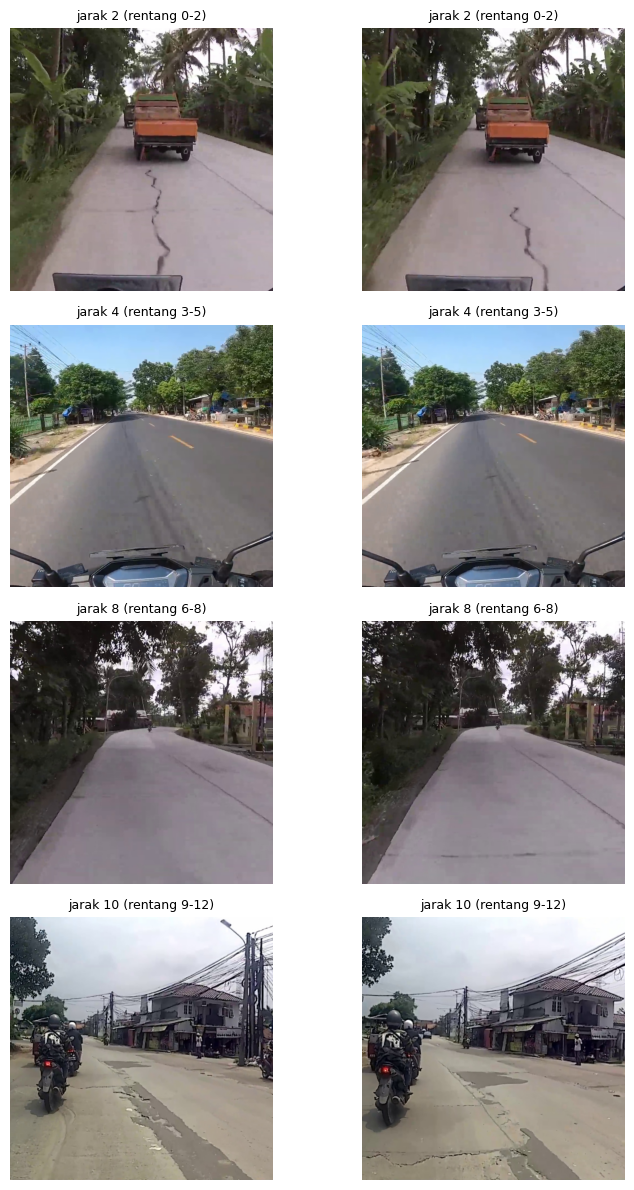

Kalau pasangan di suatu rentang masih 'adegan yang sama', TAU minimal sampai rentang itu.


In [8]:
# A5 · Lihat contoh pasangan per rentang jarak, buat menentukan TAU di sel A6
import matplotlib.pyplot as plt
def sample_pair(lo, hi):
    cand = df.index[(df.nn_dist >= lo) & (df.nn_dist <= hi)].tolist()
    if not cand: return None
    i = random.choice(cand)
    d = hamming_rows(H[i:i+1], H)[0].astype(int); d[i] = 99
    return i, int(d.argmin()), int(d.min())

bands = [(0, 2), (3, 5), (6, 8), (9, 12)]
fig, axes = plt.subplots(len(bands), 2, figsize=(8, 3 * len(bands)))
for row, (lo, hi) in enumerate(bands):
    pair = sample_pair(lo, hi)
    for col in range(2):
        ax = axes[row, col]; ax.axis("off")
        if pair:
            ax.imshow(Image.open(df.image[pair[col]])); ax.set_title(f"jarak {pair[2]} (rentang {lo}-{hi})", fontsize=9)
plt.tight_layout(); plt.show()
print("Kalau pasangan di suatu rentang masih 'adegan yang sama', TAU minimal sampai rentang itu.")

In [9]:
# A6 · Kelompokkan foto hampir kembar (jarak <= TAU)
TAU = 6   # ubah sesuai hasil sel A5, lalu jalankan ulang sel ini sampai A9

parent = list(range(len(H)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for s in range(0, len(H), 512):
    d = hamming_rows(H[s:s+512], H)
    rr, cc = np.nonzero(d <= TAU)
    for r_, c_ in zip(rr + s, cc):
        if c_ > r_:
            a, b = find(int(r_)), find(int(c_))
            if a != b: parent[b] = a
df["group"] = [find(i) for i in range(len(H))]
sizes = df.group.value_counts()
print(f"TAU = {TAU}: {len(df)} foto -> {len(sizes)} kelompok | kelompok >1 foto: {(sizes > 1).sum()} | terbesar: {sizes.max()}")

TAU = 6: 9048 foto -> 8472 kelompok | kelompok >1 foto: 351 | terbesar: 63


In [10]:
# A7 · Bagi 70:15:15 per kelompok, proporsi kelas dijaga
from sklearn.model_selection import StratifiedGroupKFold

def rarest_class(label_path):
    with open(label_path) as f:
        cs = {int(float(l.split()[0])) for l in f if l.strip()}
    return min(cs, key=lambda c: cls_counts[c]) if cs else len(CLASS_NAMES)

df["strat"] = [rarest_class(p) for p in df.label]
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
                             .split(df, df.strat, df.group)):
    fold[idx] = k
df["split"] = np.where(fold < 3, "test", np.where(fold < 6, "val", "train"))
assert df.groupby("group").split.nunique().max() == 1, "Ada kelompok yang terbelah!"

def write_split(frame, prefix, yaml_name):
    for s in ["train", "val", "test"]:
        with open(os.path.join(DS, f"{prefix}{s}.txt"), "w") as f:
            f.write("\n".join(frame.loc[frame.split == s, "image"]) + "\n")
    with open(os.path.join(DS, yaml_name), "w") as f:
        f.write(f"path: '{DS.replace(os.sep, '/')}'\ntrain: {prefix}train.txt\nval: {prefix}val.txt\ntest: {prefix}test.txt\n")
        f.write("names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASS_NAMES)))

def class_table(frame):
    out = {}
    for s in ["train", "val", "test"]:
        cnt = collections.Counter()
        for p in frame.loc[frame.split == s, "label"]:
            with open(p) as f:
                for l in f:
                    if l.strip(): cnt[int(float(l.split()[0]))] += 1
        out[s] = [cnt[i] for i in range(len(CLASS_NAMES))]
    t = pd.DataFrame(out, index=CLASS_NAMES)
    t.loc["Jumlah foto"] = [int((frame.split == s).sum()) for s in ["train", "val", "test"]]
    return t

write_split(df, "", "data.yaml")
display(class_table(df))

,train,val,test
Longitudinal Crack,3548,803,776
Lateral Crack,2395,490,547
Alligator Crack,2612,549,514
Pothole,4457,869,923
Other,1219,234,275
Jumlah foto,6398,1337,1313


In [11]:
# A8 · (Opsional) Pembagian acak tanpa pengelompokan, buat membandingkan efek kebocoran data
rnd = df.copy()
perm = np.random.RandomState(SEED).permutation(len(rnd))
n15 = int(0.15 * len(rnd))
rnd["split"] = "train"
rnd.iloc[perm[:n15], rnd.columns.get_loc("split")] = "test"
rnd.iloc[perm[n15:2 * n15], rnd.columns.get_loc("split")] = "val"
write_split(rnd, "random_", "data_random.yaml")
print(f"Pada pembagian acak, {(rnd.groupby('group').split.nunique() > 1).sum()} kelompok foto kembar terbelah.")

Pada pembagian acak, 173 kelompok foto kembar terbelah.


In [12]:
# A9 · Simpan ringkasan pembagian data
df.drop(columns=["phash"]).to_csv(os.path.join(PROJ, "split_kelompok.csv"), index=False)
n_img = len(os.listdir(os.path.join(DS, "images")))
print(f"Dataset siap di {DS}: {n_img} foto. Bagian A selesai, lanjut ke Bagian C.")
print("Kalau disk mepet, folder data/raw boleh dihapus sekarang (zip aslinya masih ada).")

Dataset siap di /home/galang/skripsi-training/Deteksi_Jalan/data/rddc: 9048 foto. Bagian A selesai, lanjut ke Bagian C.
Kalau disk mepet, folder data/raw boleh dihapus sekarang (zip aslinya masih ada).


---
## Bagian B · Audit dataset & distribusi Train/Validation/Test (tanpa training ulang)

**Khusus untuk memeriksa mengapa mAP masih rendah.** Bagian ini hanya **membaca** `split_kelompok.csv`, foto, dan label `.txt` yang **sudah ada**. Tidak melakukan download, tidak memanggil `model.train()`, tidak mengubah anotasi, dan tidak mengubah pembagian data.

**Cara pakai jika training sudah selesai:** pilih kernel `.venv-yolo`, jalankan **Sel 1 (Setup)** bila diperlukan, kemudian jalankan **B1 → B2 → B3**. **Tidak perlu menjalankan A1–A9 maupun C1–D2 lagi.** Jika lokasi `split_kelompok.csv` belum ditemukan, periksa `PROJ` atau lokasi project yang dicetak oleh B1.

- **B1:** Audit berkas gambar, keberadaan/isi label, koordinat bounding box, dan frekuensi setiap kelas. Periksa juga kemungkinan label asli tidak ada bila folder `data/raw` masih tersedia. File label yang tidak ada pada sumber berbeda dari gambar *background* yang benar-benar tidak mengandung kerusakan.
- **B2:** Periksa jumlah gambar, jumlah kotak, distribusi masing-masing kelas pada train/val/test, dan potensi kebocoran kelompok gambar antar-split.
- **B3:** Tampilkan contoh gambar + anotasi bounding box secara acak namun reproducible, termasuk contoh gambar tanpa kotak.

Laporan CSV dan PNG baru disimpan pada folder **`audit_yolo/`** di direktori project. Dataset, model `.pt`, dan file hasil eksperimen lama **tidak ditimpa**. Ini audit anotasi otomatis dan pemeriksaan sampel; validitas makna setiap label tetap memerlukan penilaian visual.

In [13]:
# B1 · Audit dataset YOLO yang sudah ada (READ-ONLY terhadap gambar, label, dan split)
from pathlib import Path
from collections import Counter
import math
import numpy as np
import pandas as pd
from IPython.display import display

AUDIT_NAMES = list(globals().get('CLASS_NAMES',
    ['Longitudinal Crack', 'Lateral Crack', 'Alligator Crack', 'Pothole', 'Other']))
AUDIT_SEED = int(globals().get('SEED', 42))

# VS Code dapat menjalankan notebook dari cwd parent, jadi coba beberapa lokasi aman.
project_candidates = [
    Path(globals().get('PROJ', Path.cwd())).expanduser(), Path.cwd(),
    Path.cwd() / 'Deteksi_Jalan', Path.home() / 'skripsi-training',
    Path.home() / 'skripsi-training' / 'Deteksi_Jalan',
]
seen_paths = set()
project_candidates = [p.resolve() for p in project_candidates
                      if not (str(p.resolve()) in seen_paths or seen_paths.add(str(p.resolve())))]
found = [p / 'split_kelompok.csv' for p in project_candidates if (p / 'split_kelompok.csv').is_file()]
if not found:
    raise FileNotFoundError(
        'split_kelompok.csv belum ditemukan. File ini dibuat oleh sel A9. '
        'Cari file tersebut pada folder project yang dipakai saat training, '
        'lalu atur PROJ = "/path/folder-project" pada Sel 1.\n'
        'Lokasi yang dicek: ' + ', '.join(map(str, project_candidates)))
AUDIT_PROJECT = found[0].parent
AUDIT_DIR = AUDIT_PROJECT / 'audit_yolo'
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
source = pd.read_csv(found[0])
needed = {'image', 'label', 'split'}
if not needed.issubset(source.columns):
    raise ValueError('Kolom split_kelompok.csv belum lengkap: ' + str(sorted(needed - set(source.columns))))
source['split'] = source['split'].astype(str).str.lower().str.strip().replace({'valid':'val', 'validation':'val'})

# Baca file secara langsung tanpa membetulkan/menghapus label apa pun.
def audit_resolve(v):
    p = Path(str(v).strip()).expanduser()
    if p.is_absolute(): return p
    for candidate in [AUDIT_PROJECT / p, AUDIT_PROJECT / 'data' / 'rddc' / p]:
        if candidate.exists(): return candidate
    return AUDIT_PROJECT / p

def audit_label(label_file):
    counts = Counter(); problems = []; total_lines = 0
    if not label_file.is_file():
        return counts, [('file', 'file label tidak ada')], 0, 'tidak_ada'
    lines = label_file.read_text(encoding='utf-8', errors='replace').splitlines()
    for ln, line in enumerate(lines, start=1):
        if not line.strip(): continue
        total_lines += 1
        t = line.split()
        if len(t) != 5:
            problems.append((ln, 'jumlah kolom bukan 5')); continue
        try:
            cl = float(t[0]); vals = list(map(float, t[1:]))
            if not math.isfinite(cl) or not cl.is_integer():
                raise ValueError('kelas bukan integer')
            cl = int(cl)
            if cl not in range(len(AUDIT_NAMES)):
                raise ValueError('kelas di luar rentang')
            if not all(math.isfinite(q) for q in vals):
                raise ValueError('koordinat bukan bilangan finite')
            x, y, w, h = vals
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                raise ValueError('koordinat/ukuran tidak valid')
            if x-w/2 < -1e-4 or x+w/2 > 1+1e-4 or y-h/2 < -1e-4 or y+h/2 > 1+1e-4:
                raise ValueError('kotak melewati batas gambar')
            counts[cl] += 1
        except (ValueError, OverflowError) as e:
            problems.append((ln, str(e)))
    status = 'kosong' if total_lines == 0 else ('bermasalah' if problems else 'berisi')
    return counts, problems, total_lines, status

rows, problems = [], []
for r in source.itertuples(index=False):
    rdict = r._asdict()
    im = audit_resolve(rdict['image']); lb = audit_resolve(rdict['label'])
    cnt, errs, total, status = audit_label(lb)
    result = dict(stem=str(rdict.get('stem', im.stem)), split=str(rdict['split']),
                  group=rdict.get('group', None), image=str(im), label=str(lb),
                  image_ada=im.is_file(), label_status=status,
                  baris_label=total, jumlah_bbox=sum(cnt.values()), jumlah_baris_bermasalah=len(errs))
    for i in range(len(AUDIT_NAMES)):
        result[f'bbox_kelas_{i}'] = cnt[i]
        result[f'foto_kelas_{i}'] = int(cnt[i] > 0)
    rows.append(result)
    for lin, issue in errs:
        problems.append({'stem': result['stem'], 'split': result['split'],
                         'label': str(lb), 'baris': lin, 'masalah': issue})

AUDIT_IMAGES = pd.DataFrame(rows)
AUDIT_ISSUES = pd.DataFrame(problems, columns=['stem','split','label','baris','masalah'])
AUDIT_IMAGES.to_csv(AUDIT_DIR/'ringkasan_gambar.csv', index=False)
AUDIT_ISSUES.to_csv(AUDIT_DIR/'temuan_label.csv', index=False)

# A2 pada notebook asli membuat file .txt kosong saat label sumber tidak ditemukan.
# Bila raw masih ada, bedakan 'label sumber hilang' dengan file kosong yang memang ada.
raw_path = AUDIT_PROJECT/'data'/'raw'
if raw_path.is_dir():
    raw_label_stems = {p.stem for p in raw_path.rglob('*.txt')}
    no_original_label = AUDIT_IMAGES[~AUDIT_IMAGES.stem.isin(raw_label_stems)]
    print(f'Label asli tidak ditemukan di data/raw berdasarkan stem: {len(no_original_label)} gambar')
    no_original_label.to_csv(AUDIT_DIR/'perlu_cek_label_sumber.csv', index=False)
else:
    print('Catatan: data/raw tidak tersedia; file .txt kosong hasil A2 TIDAK bisa dibedakan dari label sumber yang hilang.')

print('\nDATASET:', found[0], '| Total foto:', len(AUDIT_IMAGES))
print('File foto hilang:', int((~AUDIT_IMAGES.image_ada).sum()))
print('Label .txt hilang:', int((AUDIT_IMAGES.label_status=='tidak_ada').sum()))
print('Label .txt kosong:', int((AUDIT_IMAGES.label_status=='kosong').sum()))
print('Gambar tanpa bounding box valid:', int((AUDIT_IMAGES.jumlah_bbox==0).sum()))
print('Baris/berkas label bermasalah:', len(AUDIT_ISSUES))
print('\nJumlah bounding box valid per kelas:')
display(pd.DataFrame({'kelas': AUDIT_NAMES,
                      'jumlah_bbox': [int(AUDIT_IMAGES[f'bbox_kelas_{i}'].sum()) for i in range(len(AUDIT_NAMES))],
                      'jumlah_foto': [int(AUDIT_IMAGES[f'foto_kelas_{i}'].sum()) for i in range(len(AUDIT_NAMES))]}))
if len(AUDIT_ISSUES):
    display(AUDIT_ISSUES.head(20))
print('Laporan tersimpan:', AUDIT_DIR)

Label asli tidak ditemukan di data/raw berdasarkan stem: 1947 gambar

DATASET: /home/galang/skripsi-training/Deteksi_Jalan/split_kelompok.csv | Total foto: 9048
File foto hilang: 0
Label .txt hilang: 0
Label .txt kosong: 1947
Gambar tanpa bounding box valid: 1947
Baris/berkas label bermasalah: 0

Jumlah bounding box valid per kelas:


,kelas,jumlah_bbox,jumlah_foto
0,Longitudinal Crack,5127,3278
1,Lateral Crack,3432,2019
2,Alligator Crack,3675,2234
3,Pothole,6249,2917
4,Other,1728,1282


Laporan tersimpan: /home/galang/skripsi-training/Deteksi_Jalan/audit_yolo


In [14]:
# B2 · Periksa distribusi train / validation / test dan kebocoran kelompok (READ-ONLY)
if 'AUDIT_IMAGES' not in globals():
    raise RuntimeError('Jalankan sel B1 terlebih dahulu.')
order = ['train', 'val', 'test']
unknown = sorted(set(AUDIT_IMAGES.split.dropna())-set(order))
if unknown: print('PERINGATAN: nama split tidak dikenali:', unknown)

split_rows, class_rows = [], []
for part in order:
    data = AUDIT_IMAGES[AUDIT_IMAGES.split == part]
    n = len(data)
    split_rows.append({'split': part, 'jumlah_foto': n,
                       'persen_foto': round(100*n/max(1,len(AUDIT_IMAGES)),2),
                       'foto_tanpa_bbox': int((data.jumlah_bbox==0).sum()),
                       'persen_tanpa_bbox': round(100*(data.jumlah_bbox==0).mean(),2) if n else 0,
                       'jumlah_bbox': int(data.jumlah_bbox.sum()),
                       'rata_bbox_per_foto': round(data.jumlah_bbox.mean(),2) if n else 0,
                       'label_bermasalah': int((data.jumlah_baris_bermasalah>0).sum())})
    for i,name in enumerate(AUDIT_NAMES):
        class_rows.append({'split':part,'kelas':name,
                           'jumlah_bbox':int(data[f'bbox_kelas_{i}'].sum()),
                           'jumlah_foto_berkelas':int(data[f'foto_kelas_{i}'].sum()),
                           'persen_foto_berkelas':round(100*data[f'foto_kelas_{i}'].mean(),2) if n else 0})

AUDIT_SPLITS = pd.DataFrame(split_rows)
AUDIT_CLASSES = pd.DataFrame(class_rows)
AUDIT_SPLITS.to_csv(AUDIT_DIR/'distribusi_split.csv', index=False)
AUDIT_CLASSES.to_csv(AUDIT_DIR/'distribusi_kelas_per_split.csv', index=False)
print('Ringkasan rasio split (target perkiraan 70% / 15% / 15%):')
display(AUDIT_SPLITS)
print('\nJumlah bounding box per kelas dan split:')
display(AUDIT_CLASSES.pivot(index='kelas',columns='split',values='jumlah_bbox').reindex(columns=order))
print('\nPersentase foto yang mengandung masing-masing kelas pada tiap split:')
display(AUDIT_CLASSES.pivot(index='kelas',columns='split',values='persen_foto_berkelas').reindex(columns=order))
print('Catatan: satu foto dapat berisi lebih dari satu kelas. Persentase kelas tidak harus berjumlah 100%.')

if AUDIT_IMAGES.group.notna().any():
    grouped = AUDIT_IMAGES.dropna(subset=['group']).groupby('group').split.nunique()
    leaked = int((grouped > 1).sum())
    print('\nKelompok pHash yang muncul di lebih dari satu split:', leaked,
          '→' , 'PERLU DICEK!' if leaked else 'tidak ditemukan (baik)')
else:
    print('\nKolom group tidak terisi: kebocoran kelompok tidak bisa diperiksa.')

for name in AUDIT_NAMES:
    values = AUDIT_CLASSES[AUDIT_CLASSES.kelas==name].set_index('split')['jumlah_bbox']
    missing = [s for s in order if values.get(s,0)==0]
    low = [s for s in order if 0 < values.get(s,0) < 10]
    if missing: print(f'PERINGATAN: {name} tidak ada bounding box valid di: {missing}')
    if low: print(f'PERHATIAN: {name} hanya memiliki <10 bounding box di: {low}')
    # Perbandingan persentase gambar per kelas agar kelas langka antar-split mudah ditemukan.
    # Ambang <50% tingkat kemunculan train adalah heuristik inspeksi, bukan bukti split salah.
    rates = AUDIT_CLASSES[AUDIT_CLASSES.kelas==name].set_index('split')
    train_rate = float(rates.loc['train','persen_foto_berkelas']) if 'train' in rates.index else 0
    train_count = int(rates.loc['train','jumlah_bbox']) if 'train' in rates.index else 0
    for subset in ['val','test']:
        if subset in rates.index and train_count >= 10 and train_rate > 0:
            subset_rate = float(rates.loc[subset,'persen_foto_berkelas'])
            if 0 < subset_rate < 0.5 * train_rate:
                print(f'PERHATIAN: {name} jauh lebih jarang di {subset} '
                      f'({subset_rate:.2f}% foto) dibanding train ({train_rate:.2f}% foto).')
print('\nTabel disimpan di:', AUDIT_DIR)

Ringkasan rasio split (target perkiraan 70% / 15% / 15%):


,split,jumlah_foto,persen_foto,foto_tanpa_bbox,persen_tanpa_bbox,jumlah_bbox,rata_bbox_per_foto,label_bermasalah
0,train,6398,70.71,1376,21.51,14231,2.22,0
1,val,1337,14.78,273,20.42,2945,2.20,0
2,test,1313,14.51,298,22.70,3035,2.31,0



Jumlah bounding box per kelas dan split:


split,train,val,test
kelas,,,
Alligator Crack,2612,549,514
Lateral Crack,2395,490,547
Longitudinal Crack,3548,803,776
Other,1219,234,275
Pothole,4457,869,923



Persentase foto yang mengandung masing-masing kelas pada tiap split:


split,train,val,test
kelas,,,
Alligator Crack,24.84,25.36,23.31
Lateral Crack,22.19,21.77,23.46
Longitudinal Crack,36.00,37.25,36.33
Other,14.21,13.31,14.85
Pothole,32.15,33.43,31.45


Catatan: satu foto dapat berisi lebih dari satu kelas. Persentase kelas tidak harus berjumlah 100%.

Kelompok pHash yang muncul di lebih dari satu split: 0 → tidak ditemukan (baik)

Tabel disimpan di: /home/galang/skripsi-training/Deteksi_Jalan/audit_yolo


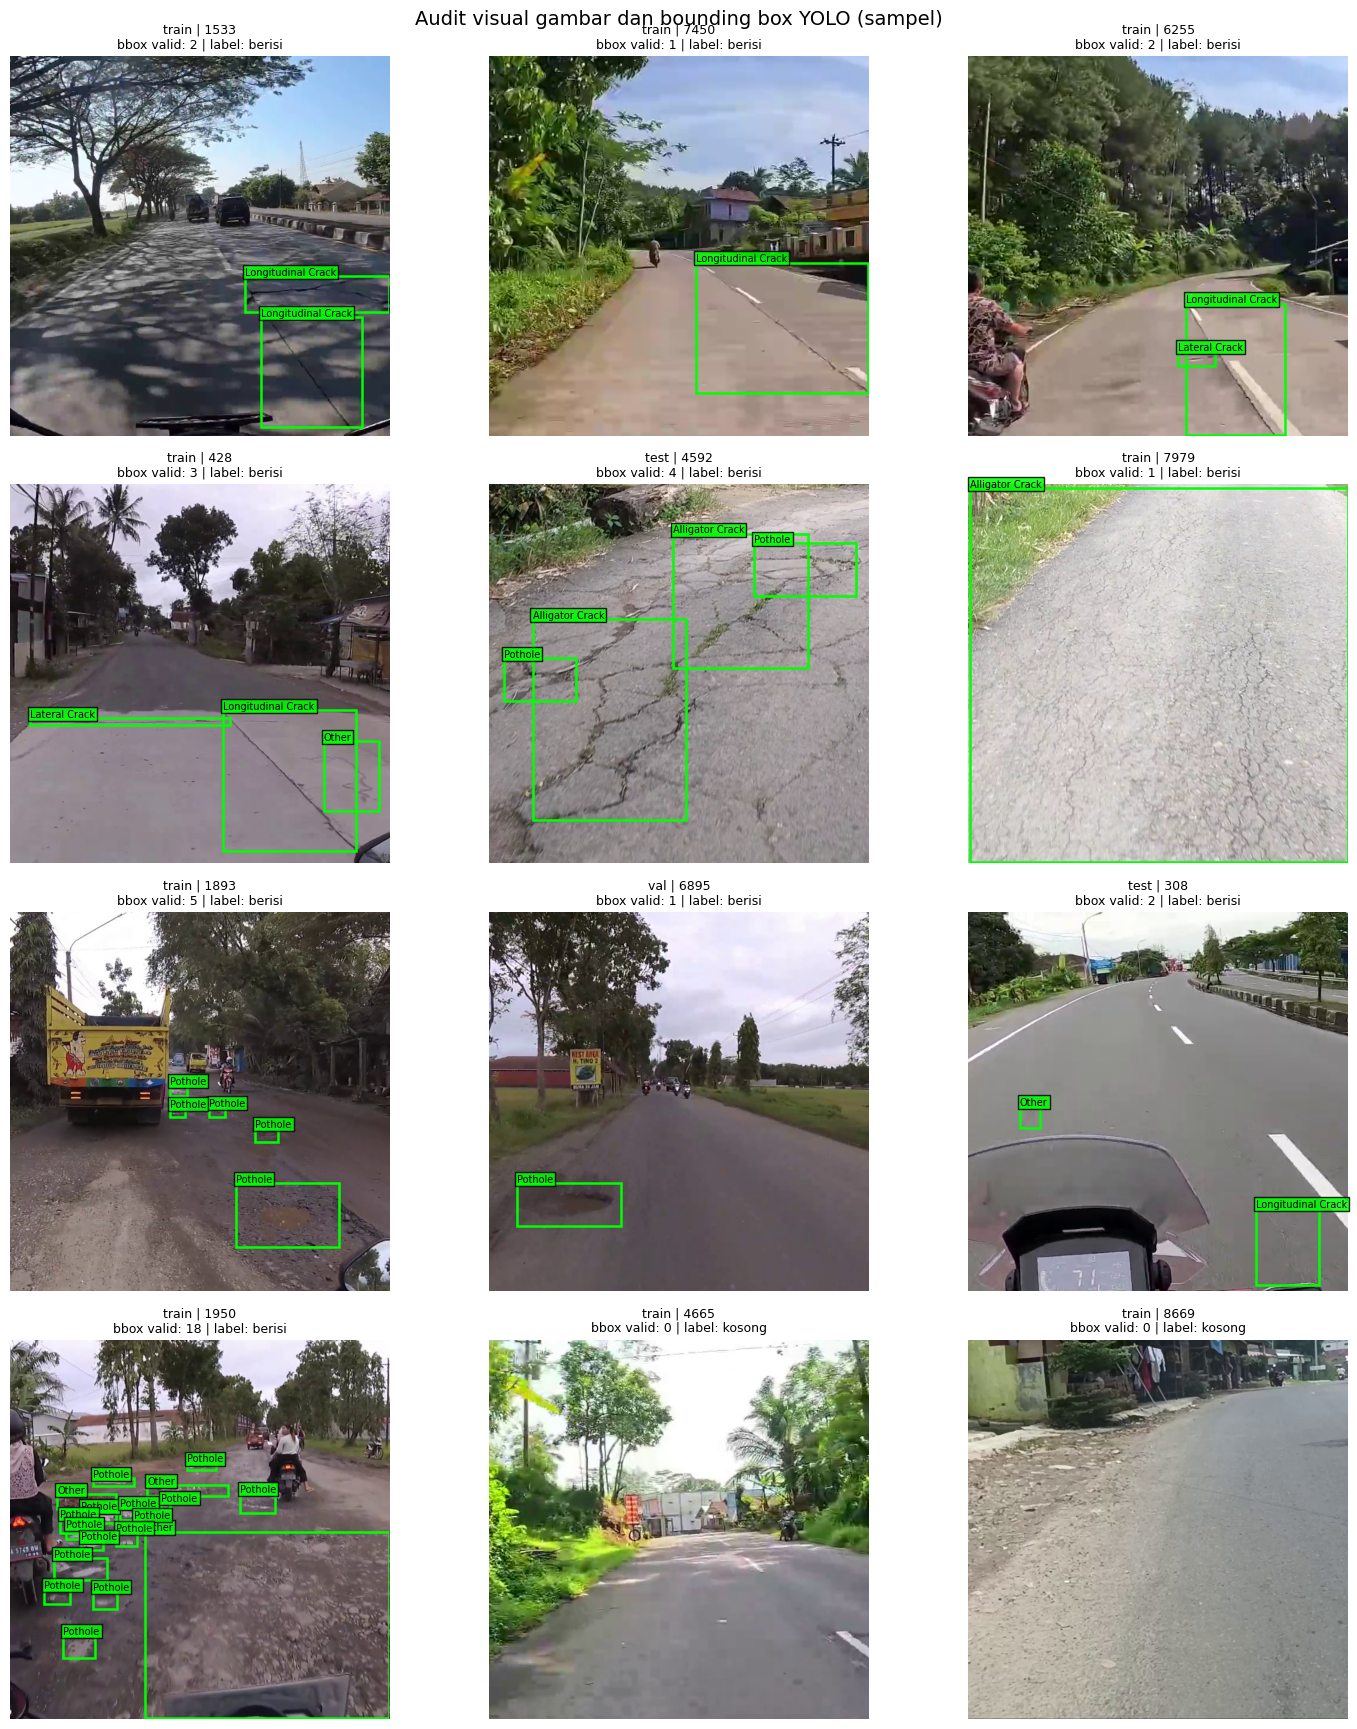

Gambar audit disimpan: /home/galang/skripsi-training/Deteksi_Jalan/audit_yolo/contoh_bounding_box.png
Catatan: gambar tanpa bbox harus diperiksa manual: benar-benar background atau label terlewat?


In [15]:
# B3 · Periksa contoh gambar + bounding box (READ-ONLY, tidak mengubah anotasi)
if 'AUDIT_IMAGES' not in globals():
    raise RuntimeError('Jalankan sel B1 terlebih dahulu.')
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

rng = np.random.default_rng(AUDIT_SEED)
selected = []
def choose_one(data):
    if len(data)==0: return
    candidates = data[data.image_ada & ~data.index.isin(selected)]
    if len(candidates):
        selected.append(int(rng.choice(candidates.index.to_numpy())))

# Pilih contoh tiap kelas (termasuk kelas langka), lalu 2 background dan 1 label bermasalah.
for i in range(len(AUDIT_NAMES)):
    choose_one(AUDIT_IMAGES[AUDIT_IMAGES[f'foto_kelas_{i}']>0])
    choose_one(AUDIT_IMAGES[AUDIT_IMAGES[f'foto_kelas_{i}']>0])
choose_one(AUDIT_IMAGES[AUDIT_IMAGES.jumlah_bbox==0])
choose_one(AUDIT_IMAGES[AUDIT_IMAGES.jumlah_bbox==0])
choose_one(AUDIT_IMAGES[AUDIT_IMAGES.jumlah_baris_bermasalah>0])
if not selected:
    print('Tidak ada file gambar yang dapat ditampilkan. Periksa path pada laporan B1.')
else:
    ncols=3; nrows=int(np.ceil(len(selected)/ncols))
    fig, axes = plt.subplots(nrows,ncols,figsize=(15,4.4*nrows),squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax,idx in zip(axes.ravel(), selected):
        row = AUDIT_IMAGES.loc[idx]
        try:
            with Image.open(row['image']) as opened:
                img = opened.convert('RGB')
            w_img,h_img=img.size
            ax.imshow(img)
            if Path(row['label']).is_file():
                for line in Path(row['label']).read_text(encoding='utf-8',errors='replace').splitlines():
                    t=line.split()
                    if len(t)!=5: continue
                    try:
                        raw_cls = float(t[0]); x,y,w,h=map(float,t[1:])
                        if not (np.isfinite(raw_cls) and raw_cls.is_integer() and
                                0<=int(raw_cls)<len(AUDIT_NAMES) and
                                all(np.isfinite(q) for q in (x,y,w,h)) and
                                0<=x<=1 and 0<=y<=1 and 0<w<=1 and 0<h<=1 and
                                x-w/2>=-1e-4 and x+w/2<=1+1e-4 and
                                y-h/2>=-1e-4 and y+h/2<=1+1e-4): continue
                        cl=int(raw_cls)
                        bx,by=(x-w/2)*w_img,(y-h/2)*h_img
                        ax.add_patch(patches.Rectangle((bx,by),w*w_img,h*h_img,
                                                        fill=False,edgecolor='lime',linewidth=1.8))
                        ax.text(bx,max(0,by-3),AUDIT_NAMES[cl],color='black',fontsize=7,
                                bbox={'facecolor':'lime','alpha':0.85,'pad':1.5})
                    except (ValueError,OverflowError): continue
            ax.set_title(f"{row['split']} | {row['stem']}\n"
                         f"bbox valid: {row['jumlah_bbox']} | label: {row['label_status']}", fontsize=9)
        except Exception as e:
            ax.text(.5,.5, f'Gagal membuka gambar:\n{type(e).__name__}: {str(e)[:90]}',
                    ha='center',va='center',transform=ax.transAxes,fontsize=9)
    fig.suptitle('Audit visual gambar dan bounding box YOLO (sampel)',fontsize=14)
    plt.tight_layout()
    png = AUDIT_DIR/'contoh_bounding_box.png'
    fig.savefig(png,dpi=150,bbox_inches='tight')
    plt.show()
    print('Gambar audit disimpan:',png)
print('Catatan: gambar tanpa bbox harus diperiksa manual: benar-benar background atau label terlewat?')

---
## Bagian C · Training

Daftar eksperimen. Ganti `MODEL` dan `SKEMA` di sel C1, lalu jalankan C1 sampai C4. Satu eksperimen bisa makan beberapa jam (tergantung GPU), jadi colok charger dan atur supaya laptop tidak *sleep*.

Pengaturan: maksimal 15 epoch, *early stopping* (berhenti kalau 5 epoch berturut-turut tidak membaik). Tiap eksperimen menghasilkan:
- `best.pt`: model di epoch dengan mAP50-95 validasi tertinggi
- `last.pt`: model di epoch terakhir yang dijalankan
- `log_per_epoch.txt` dan `results.csv`: detail tiap epoch
- `grafik_per_epoch.png`: grafik loss dan metrik

Semuanya ada di `runs/<nama eksperimen>/`, dan salinan kedua model ada di `models/`.

| No | MODEL | SKEMA | Selesai |
|---|---|---|---|
| 1 | yolov8s.pt | A | ☐ |
| 2 | yolov8s.pt | B | ☐ |
| 3 | yolo11s.pt | A | ☐ |
| 4 | yolo11s.pt | B | ☐ |
| 5 | yolo26s.pt | A | ☐ |
| 6 | yolo26s.pt | B | ☐ |
| Opsional | yolo11s.pt | A, `SPLIT = "acak"` | ☐ |

Skema A = augmentasi bawaan YOLO. Skema B = bawaan + kecerahan, kontras, silau, bayangan.

In [11]:
# C1 · Pilih eksperimen
MODEL = "yolo11s.pt"     # "yolov8s.pt", "yolo11s.pt", atau "yolo26s.pt"
SKEMA = "A"              # "A" = augmentasi bawaan, "B" = bawaan + augmentasi cuaca
SPLIT = "kelompok"       # "kelompok" (utama) atau "acak" (opsional, pembanding kebocoran)

import albumentations as A
NAME = f"{os.path.splitext(MODEL)[0]}_{SKEMA}" + ("_acak" if SPLIT == "acak" else "")
DATA = os.path.join(DS, "data.yaml" if SPLIT == "kelompok" else "data_random.yaml")

EPOCHS = 15        # jumlah epoch maksimum
PATIENCE = 5       # early stopping: berhenti kalau 5 epoch berturut-turut mAP50-95 validasi tidak naik
CLOSE_MOSAIC = 3   # mosaic dimatikan di 3 epoch terakhir (bawaan 10, terlalu banyak untuk 15 epoch)

BATCH = 16         # kalau muncul "CUDA out of memory", turunkan ke 8 (lalu pakai 8 juga untuk semua eksperimen)
WORKERS = 4        # proses pembaca data. Kalau error DataLoader atau "paging file is too small", ganti ke 2 atau 0

COMMON = dict(data=DATA, epochs=EPOCHS, patience=PATIENCE, close_mosaic=CLOSE_MOSAIC,
              imgsz=640, batch=BATCH, workers=WORKERS, seed=SEED, optimizer="auto",
              project=RUNS, name=NAME, exist_ok=True)

AUG_B = [
    A.Blur(p=0.01), A.MedianBlur(p=0.01), A.ToGray(p=0.01), A.CLAHE(p=0.01),   # bawaan Ultralytics, tetap dipertahankan
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3),  # kecerahan dan kontras
        A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5)),                            # silau dari arah langit
        A.RandomShadow(shadow_roi=(0, 0.5, 1, 1)),                              # bayangan di area jalan
    ], p=0.5),
]
print("Eksperimen:", NAME, "| data:", os.path.basename(DATA))

Eksperimen: yolo11s_A | data: data.yaml


In [ ]:
# C2 · (Opsional) Lihat contoh hasil augmentasi Skema B sebelum training
import matplotlib.pyplot as plt
samples = random.sample(open(os.path.join(DS, "train.txt")).read().splitlines(), 2)
previews = [("Asli", None),
            ("Kecerahan/kontras", A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1)),
            ("Silau", A.RandomSunFlare(flare_roi=(0, 0, 1, 0.5), p=1)),
            ("Bayangan", A.RandomShadow(shadow_roi=(0, 0.5, 1, 1), p=1))]
fig, axes = plt.subplots(len(samples), len(previews), figsize=(4 * len(previews), 3 * len(samples)))
for r, path in enumerate(samples):
    img = np.array(Image.open(path).convert("RGB"))
    for c, (title, t) in enumerate(previews):
        ax = axes[r, c]; ax.axis("off"); ax.set_title(title, fontsize=10)
        ax.imshow(img if t is None else t(image=img)["image"])
plt.tight_layout(); plt.show()

In [ ]:
# C3 · Training: early stopping, checkpoint best/last, log per epoch
import time, datetime, torch
from ultralytics import YOLO

RUN_DIR = os.path.join(RUNS, NAME)
MODELS = os.path.join(PROJ, "models")        # salinan model dengan nama jelas
os.makedirs(MODELS, exist_ok=True)

def log_write(tr, text):
    print(text)
    with open(os.path.join(tr.save_dir, "log_per_epoch.txt"), "a", encoding="utf-8") as f:
        f.write(text + "\n")

def log_header(tr):
    log_write(tr, f"=== {NAME} | mulai {datetime.datetime.now():%Y-%m-%d %H:%M} | epoch {tr.start_epoch + 1}-{tr.epochs} "
                  f"| patience {tr.args.patience} | optimizer {type(tr.optimizer).__name__} ===")

def log_epoch(tr):
    ep, m = tr.epoch + 1, tr.metrics or {}
    if getattr(tr, "_log_selesai", False):   # dipanggil lagi oleh validasi akhir best.pt setelah training
        log_write(tr, f"Validasi akhir best.pt (epoch {tr.stopper.best_epoch}): "
                      f"P {m.get('metrics/precision(B)', 0):.4f} R {m.get('metrics/recall(B)', 0):.4f} "
                      f"mAP50 {m.get('metrics/mAP50(B)', 0):.4f} mAP50-95 {m.get('metrics/mAP50-95(B)', 0):.4f}")
        return
    losses = tr.label_loss_items(tr.tloss, prefix="train")
    is_best = tr.fitness is not None and tr.best_fitness is not None and tr.fitness >= tr.best_fitness
    line = (f"Epoch {ep:>2}/{tr.epochs} | {tr.epoch_time:5.0f} dtk | "
            + " ".join(f"{k.split('/')[-1]} {float(v):.4f}" for k, v in losses.items())
            + f" | P {m.get('metrics/precision(B)', 0):.4f} R {m.get('metrics/recall(B)', 0):.4f}"
            + f" mAP50 {m.get('metrics/mAP50(B)', 0):.4f} mAP50-95 {m.get('metrics/mAP50-95(B)', 0):.4f}"
            + f" | lr {tr.lr.get('lr/pg0', 0):.6f}"
            + (" | TERBAIK -> best.pt" if is_best else f" | terbaik masih epoch {tr.stopper.best_epoch}"))
    log_write(tr, line)
    if tr.stop:
        tr._log_selesai = True
        if ep < tr.epochs:
            log_write(tr, f">>> Early stopping: {tr.args.patience} epoch tanpa peningkatan, training berhenti di epoch {ep}.")

def with_logging(model):
    model.add_callback("on_train_start", log_header)
    model.add_callback("on_fit_epoch_end", log_epoch)
    return model

def simpan_model():
    w = os.path.join(RUN_DIR, "weights")
    for src, tag in [("best.pt", "best"), ("last.pt", "last")]:
        shutil.copy2(os.path.join(w, src), os.path.join(MODELS, f"{NAME}_{tag}.pt"))
    res = pd.read_csv(os.path.join(RUN_DIR, "results.csv")); res.columns = res.columns.str.strip()
    b = res["metrics/mAP50-95(B)"].idxmax()
    print(f"\nEpoch terbaik: {int(res.loc[b, 'epoch'])} dari {len(res)} epoch "
          f"(mAP50-95 validasi {res.loc[b, 'metrics/mAP50-95(B)']:.4f})")
    print("Model terbaik :", os.path.join(MODELS, f"{NAME}_best.pt"))
    print("Model terakhir:", os.path.join(MODELS, f"{NAME}_last.pt"))

last = os.path.join(RUN_DIR, "weights", "last.pt")
status = "baru"
if os.path.exists(last):
    ck = torch.load(last, map_location="cpu", weights_only=False)
    status = "selesai" if ck.get("epoch", -1) == -1 else "lanjut"

if status == "selesai":
    print(f"{NAME} sudah selesai training. Kalau mau training ulang dari nol, hapus dulu folder {RUN_DIR}")
elif status == "lanjut":
    print(f"Melanjutkan {NAME} dari checkpoint terakhir...")
    with_logging(YOLO(last)).train(resume=True)
else:
    kwargs = dict(COMMON)
    if SKEMA == "B":
        kwargs["augmentations"] = AUG_B
    with_logging(YOLO(MODEL)).train(**kwargs)
simpan_model()

In [ ]:
# C4 · Lihat log dan grafik per epoch
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
log_path = os.path.join(RUN_DIR, "log_per_epoch.txt")
if os.path.exists(log_path):
    print(open(log_path, encoding="utf-8").read())

res = pd.read_csv(os.path.join(RUN_DIR, "results.csv")); res.columns = res.columns.str.strip()
ib = res["metrics/mAP50-95(B)"].idxmax(); best_ep = int(res.loc[ib, "epoch"])
display(res.drop(columns=["time", "lr/pg1", "lr/pg2"], errors="ignore").set_index("epoch").round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for k, color in [("box_loss", "C0"), ("cls_loss", "C1"), ("dfl_loss", "C2")]:
    ax1.plot(res.epoch, res[f"train/{k}"], color=color, marker="o", ms=3, label=f"{k} latih")
    ax1.plot(res.epoch, res[f"val/{k}"], color=color, marker="o", ms=3, ls="--", label=f"{k} validasi")
ax1.set_title("Loss per epoch (garis putus-putus = validasi)")
for col, lab in [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall"),
                 ("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")]:
    ax2.plot(res.epoch, res[col], marker="o", ms=3, label=lab)
ax2.plot(best_ep, res.loc[ib, "metrics/mAP50-95(B)"], "k*", ms=11, label="best.pt")
ax2.set_title("Metrik validasi per epoch")
for ax in (ax1, ax2):
    ax.axvline(best_ep, color="gray", ls=":", lw=1)
    ax.set_xlabel("Epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax2.annotate(f"terbaik: epoch {best_ep}", xy=(best_ep, 0), xycoords=("data", "axes fraction"),
             xytext=(4, 4), textcoords="offset points", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "grafik_per_epoch.png"), dpi=150)
plt.show()

---
## Bagian C5–C8 · Fine-tuning dari model 15 epoch (TANPA mengulang dari awal)

**Gunakan bagian ini setelah eksperimen 15 epoch selesai.** Model sumber adalah `best.pt` dari `runs/<nama eksperimen>/weights/` atau salinannya di `models/`. Notebook akan melatih **45 epoch tambahan** dengan bobot tersebut, kemudian menyimpan checkpoint dan hasil evaluasi di folder **baru**.

- **Tidak perlu menjalankan Sel 0, Bagian A, B, C2, C3, atau C4 ulang.** Setelah membuka VS Code, cukup jalankan **Sel 1 (Setup)** → **C1 (pilih MODEL/SKEMA/SPLIT yang sudah dilatih)** → **C5 → C6 → C7 → C8**.
- C5: pilih sumber, periksa file, dan atur 45 epoch tambahan. C6: mulai fine-tuning; jika terputus, dapat mencoba `resume=True` dari `last.pt` fine-tune. C7: grafik training awal vs fine-tuning. C8: evaluasi pada **test set yang sama** dan tabel perbandingan.
- `45 epoch tambahan` berarti maksimum **15 epoch awal + 45 epoch fase baru**, **bukan** satu training kontinu 60 epoch: optimizer dan scheduler dimulai lagi dengan learning rate yang lebih rendah.
- **Jangan jalankan Run All**: cell persiapan data dan C3 tidak perlu diulang untuk fine-tuning. Jangan mengganti split/dataset atau jumlah kelas ketika membandingkan hasil.
- Untuk 60 epoch **dari awal**, tetap gunakan Bagian C3 pada eksperimen yang baru. Bagian ini memang khusus **fine-tuning dari checkpoint lama**.


In [12]:
# C5 · Konfigurasi fine-tuning dari best.pt hasil 15 epoch (TIDAK melatih dulu)
from pathlib import Path
from ultralytics import YOLO
import os

# Pastikan Sel 1 + C1 sudah dijalankan. C1 memilih MODEL, SKEMA, SPLIT, NAME, DATA.
for variabel in ("PROJ", "RUNS", "NAME", "DATA", "MODEL", "SKEMA", "SPLIT", "SEED"):
    if variabel not in globals():
        raise RuntimeError(f"Variabel {variabel} belum ada. Jalankan Sel 1 (Setup) dan C1 terlebih dahulu.")

FT_EPOCHS = 45           # 45 epoch TAMBAHAN, tidak menghitung ulang 15 epoch lama
FT_PATIENCE = 15         # early stopping berdasarkan metrik validasi
FT_BATCH = 8             # konservatif untuk GTX 1080 Ti (boleh 16 jika VRAM cukup)
FT_WORKERS = 2           # lebih ringan untuk CPU/RAM WSL2
FT_CLOSE_MOSAIC = 10
FT_LR0 = 0.0005          # learning rate rendah untuk fine-tuning
FT_IMGSZ = 640

FT_BASE_NAME = NAME      # contoh: yolo11s_A, yolo11s_B, yolov8s_A
FT_NAME = f"{FT_BASE_NAME}_finetune{FT_EPOCHS}"
FT_RUN_DIR = Path(RUNS) / FT_NAME
FT_DATA = Path(DATA)

# Cek dua tempat penyimpanan model lama: runs/ atau models/.
FT_SOURCES = [
    Path(RUNS) / FT_BASE_NAME / "weights" / "best.pt",
    Path(PROJ) / "models" / f"{FT_BASE_NAME}_best.pt",
]
FT_SOURCE = next((p for p in FT_SOURCES if p.is_file()), None)
if FT_SOURCE is None:
    raise FileNotFoundError(
        "best.pt hasil 15 epoch belum ditemukan. Lokasi yang dicari:\n" +
        "\n".join(map(str, FT_SOURCES)) +
        "\nPeriksa MODEL/SKEMA/SPLIT di C1 dan lokasi Folder Project pada Sel 1."
    )
if not FT_DATA.is_file():
    raise FileNotFoundError(f"data.yaml tidak ditemukan: {FT_DATA}. Jangan membuat split baru; gunakan yang lama.")

# Periksa bahwa model checkpoint dan dataset memiliki kelas yang konsisten.
ft_probe = YOLO(str(FT_SOURCE))
if len(ft_probe.names) != len(CLASS_NAMES):
    raise ValueError(f"Checkpoint memiliki {len(ft_probe.names)} kelas, sedangkan dataset saat ini {len(CLASS_NAMES)} kelas.")
del ft_probe

print("Model asal       :", FT_BASE_NAME)
print("Checkpoint asal  :", FT_SOURCE)
print("Dataset/split    :", FT_DATA)
print("Folder hasil baru:", FT_RUN_DIR)
print(f"Tambahan         : maksimum {FT_EPOCHS} epoch | batch {FT_BATCH} | lr0 {FT_LR0}")
print("Eksperimen lama TIDAK akan ditimpa.")


Model asal       : yolo11s_A
Checkpoint asal  : /home/galang/skripsi-training/Deteksi_Jalan/runs/yolo11s_A/weights/best.pt
Dataset/split    : /home/galang/skripsi-training/Deteksi_Jalan/data/rddc/data.yaml
Folder hasil baru: /home/galang/skripsi-training/Deteksi_Jalan/runs/yolo11s_A_finetune45
Tambahan         : maksimum 45 epoch | batch 8 | lr0 0.0005
Eksperimen lama TIDAK akan ditimpa.


In [14]:
# C6 · MULAI FINE-TUNING / lanjut dari checkpoint fine-tuning jika terputus
# HANYA jalankan setelah C5. Tidak memakai optimizer/checkpoint sebagai resume dari 15 epoch lama.
from pathlib import Path
from ultralytics import YOLO
import torch

ft_last = FT_RUN_DIR / "weights" / "last.pt"
ft_best = FT_RUN_DIR / "weights" / "best.pt"

if ft_last.is_file():
    # Resume hanya untuk run fine-tuning yang BELUM selesai.
    ft_ck = torch.load(str(ft_last), map_location="cpu", weights_only=False)
    ft_epoch = int(ft_ck.get("epoch", -1))
    del ft_ck
    if ft_epoch == -1:
        print("Fine-tuning sudah selesai. Tidak melakukan training ulang:", FT_RUN_DIR)
    else:
        print(f"Fine-tuning sebelumnya terputus pada epoch {ft_epoch + 1}; mencoba resume...")
        YOLO(str(ft_last)).train(resume=True)
else:
    # Hindari menimpa hasil ketika ada folder run tanpa last.pt (misalnya run gagal di tengah penulisan).
    if FT_RUN_DIR.exists() and any(FT_RUN_DIR.iterdir()):
        raise RuntimeError(
            f"Folder fine-tune sudah berisi file tetapi last.pt tidak ditemukan: {FT_RUN_DIR}\n"
            "Periksa folder tersebut; jangan hapus hasil eksperimen secara sembarangan."
        )

    ft_kwargs = dict(
        data=str(FT_DATA),
        epochs=FT_EPOCHS,
        patience=FT_PATIENCE,
        imgsz=FT_IMGSZ,
        batch=FT_BATCH,
        workers=FT_WORKERS,
        close_mosaic=FT_CLOSE_MOSAIC,
        optimizer="AdamW",        # eksplisit agar lr0 tidak diabaikan oleh optimizer='auto'
        lr0=FT_LR0,
        seed=SEED,
        device=0 if torch.cuda.is_available() else "cpu",
        project=str(RUNS),
        name=FT_NAME,
        exist_ok=True,
        resume=False,            # ini fase BARU dari bobot lama, bukan resume optimizer 15 epoch
        plots=True,
    )
    if SKEMA == "B":
        ft_kwargs["augmentations"] = AUG_B  # pertahankan skema augmentasi B seperti di C3

    print("Memulai fine-tuning dari:", FT_SOURCE)
    YOLO(str(FT_SOURCE)).train(**ft_kwargs)

print("Selesai/berhenti. Folder run:", FT_RUN_DIR)
print("best.pt tersedia:", ft_best.is_file())
print("last.pt tersedia:", ft_last.is_file())


Fine-tuning sebelumnya terputus pada epoch 31; mencoba resume...
New https://pypi.org/project/ultralytics/8.4.194 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.190 🚀 Python-3.10.22 torch-2.6.0+cu118 CUDA:0 (NVIDIA GeForce GTX 1080 Ti, 11264MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/galang/skripsi-training/Deteksi_Jalan/data/rddc/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=45, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0

Exception in thread Thread-55 (_pin_memory_loop):
Traceback (most recent call last):
  File "/home/galang/.local/share/uv/python/cpython-3.10-linux-x86_64-gnu/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/home/galang/.local/share/uv/python/cpython-3.10-linux-x86_64-gnu/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/home/galang/skripsi-training/.venv-yolo/lib/python3.10/site-packages/torch/utils/data/_utils/pin_memory.py", line 59, in _pin_memory_loop
    do_one_step()
  File "/home/galang/skripsi-training/.venv-yolo/lib/python3.10/site-packages/torch/utils/data/_utils/pin_memory.py", line 35, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/home/galang/.local/share/uv/python/cpython-3.10-linux-x86_64-gnu/lib/python3.10/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
  File "/home/galang/skripsi-training/.venv-yolo/lib/python3.10/

      33/45         3G      1.611      2.318       1.63         28        640: 60% ━━━━━━━───── 481/800 1.9it/s 3:04<2:47


KeyboardInterrupt: 

In [ ]:
# C7 · Grafik 15 epoch awal vs epoch fine-tuning (hanya membaca results.csv)
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

p_awal = Path(RUNS) / FT_BASE_NAME / "results.csv"
p_ft = FT_RUN_DIR / "results.csv"
if not p_awal.exists() or not p_ft.exists():
    raise FileNotFoundError("results.csv training awal / fine-tuning belum ditemukan. Pastikan C6 selesai.")

awal = pd.read_csv(p_awal); awal.columns = awal.columns.str.strip()
baru = pd.read_csv(p_ft); baru.columns = baru.columns.str.strip()
kolom = "metrics/mAP50-95(B)"
if kolom not in awal or kolom not in baru:
    raise KeyError(f"Kolom {kolom} tidak ditemukan pada salah satu results.csv")

# Sambungkan sumbu epoch hanya untuk visualisasi; optimizer dimulai ulang pada awal fase fine-tune.
e_awal = pd.to_numeric(awal["epoch"], errors="raise").to_numpy()
e_baru = pd.to_numeric(baru["epoch"], errors="raise").to_numpy() + len(awal)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
for metrik, ax, judul in [
    ("metrics/mAP50(B)", axs[0], "mAP@50 pada Validation"),
    ("metrics/mAP50-95(B)", axs[1], "mAP@50:95 pada Validation"),
]:
    ax.plot(e_awal, awal[metrik], "o-", markersize=3, label="Training awal")
    ax.plot(e_baru, baru[metrik], "o-", markersize=3, label="Fine-tuning dari best.pt")
    ax.axvline(len(awal) + 0.5, ls="--", color="gray", alpha=0.7)
    ax.set_title(judul); ax.set_xlabel("Epoch (gabungan visual)")
    ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
path_grafik = FT_RUN_DIR / "grafik_banding_awal_dan_finetune.png"
fig.savefig(path_grafik, dpi=150, bbox_inches="tight")
plt.show()

print("Epoch awal tercatat     :", len(awal))
print("Epoch fine-tune tercatat:", len(baru))
print("mAP50-95 val terbaik awal:", round(awal[kolom].max(), 5))
print("mAP50-95 val terbaik FT  :", round(baru[kolom].max(), 5))
print("Grafik tersimpan:", path_grafik)
print("CATATAN: Ini dua fase training berbeda, bukan satu run 60 epoch kontinu.")


In [ ]:
# C8 · Evaluasi best.pt hasil fine-tune pada TEST SET yang sama (bukan validation)
# Menyimpan satu baris BARU di hasil_evaluasi.csv; hasil eksperimen awal tetap ada.
from ultralytics import YOLO
import numpy as np
import pandas as pd
from pathlib import Path

p_best_ft = FT_RUN_DIR / "weights" / "best.pt"
if not p_best_ft.is_file():
    raise FileNotFoundError(f"Checkpoint fine-tuning belum tersedia: {p_best_ft}")

print("Evaluasi TEST dari:", p_best_ft)
print("Dataset yang sama:", FT_DATA)
met = YOLO(str(p_best_ft)).val(
    data=str(FT_DATA), split="test", imgsz=FT_IMGSZ,
    batch=FT_BATCH, workers=FT_WORKERS, plots=True,
    project=str(Path(PROJ) / "eval"), name=FT_NAME, exist_ok=True,
)

p = float(met.results_dict["metrics/precision(B)"])
r = float(met.results_dict["metrics/recall(B)"])
row = {
    "eksperimen": FT_NAME,
    "model": MODEL,
    "skema": SKEMA,
    "split": SPLIT,
    "precision": p,
    "recall": r,
    "F1": 2 * p * r / (p + r) if p + r else 0.0,
    "mAP50": float(met.results_dict["metrics/mAP50(B)"]),
    "mAP50-95": float(met.results_dict["metrics/mAP50-95(B)"]),
    "inferensi_ms_per_foto": float(met.speed["inference"]),
}
map_kelas = dict(zip([int(v) for v in met.box.ap_class_index], [float(v) for v in met.box.ap50]))
for i, kelas in enumerate(CLASS_NAMES):
    row[f"AP50 {kelas}"] = map_kelas.get(i, float("nan"))

p_csv = Path(PROJ) / "hasil_evaluasi.csv"
hasil = pd.read_csv(p_csv) if p_csv.is_file() else pd.DataFrame()
if not hasil.empty:
    hasil = hasil.loc[hasil["eksperimen"] != FT_NAME]
hasil = pd.concat([hasil, pd.DataFrame([row])], ignore_index=True)
hasil.to_csv(p_csv, index=False)

pilihan = hasil[hasil["eksperimen"].isin([FT_BASE_NAME, FT_NAME])]
print("\nPerbandingan hasil TEST (bila hasil awal sudah pernah dievaluasi):")
display(pilihan[["eksperimen", "precision", "recall", "F1", "mAP50", "mAP50-95"]].round(4))
print("Laporan tersimpan:", p_csv)
print("Hasil test hanya dipakai untuk pelaporan, bukan memilih checkpoint atau threshold.")


---
## Bagian D · Evaluasi di data uji

Evaluasi memakai `best.pt`. Model ini dipilih berdasarkan data validasi, jadi data uji tetap belum pernah dipakai sama sekali selama training dan hasilnya adil.

In [ ]:
# D1 · Evaluasi model terbaik di data uji, simpan ke hasil_evaluasi.csv
from ultralytics import YOLO
best = os.path.join(RUNS, NAME, "weights", "best.pt")
m = YOLO(best).val(data=DATA, split="test", imgsz=640, batch=BATCH, workers=WORKERS,
                   project=os.path.join(PROJ, "eval"), name=NAME, exist_ok=True)

P, R = m.results_dict["metrics/precision(B)"], m.results_dict["metrics/recall(B)"]
row = {"eksperimen": NAME, "model": MODEL, "skema": SKEMA, "split": SPLIT,
       "precision": P, "recall": R, "F1": 2 * P * R / (P + R) if P + R else 0.0,
       "mAP50": m.results_dict["metrics/mAP50(B)"], "mAP50-95": m.results_dict["metrics/mAP50-95(B)"],
       "inferensi_ms_per_foto": m.speed["inference"]}
ap50 = dict(zip([int(i) for i in m.box.ap_class_index], [float(v) for v in m.box.ap50]))
for i, n in enumerate(CLASS_NAMES):
    row[f"AP50 {n}"] = ap50.get(i, float("nan"))

csv_path = os.path.join(PROJ, "hasil_evaluasi.csv")
hasil = pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame()
if len(hasil):
    hasil = hasil[hasil.eksperimen != NAME]
hasil = pd.concat([hasil, pd.DataFrame([row])], ignore_index=True)
hasil.to_csv(csv_path, index=False)
display(pd.DataFrame([row]).T.rename(columns={0: NAME}))

In [ ]:
# D2 · Tabel semua eksperimen yang sudah dievaluasi
display(pd.read_csv(os.path.join(PROJ, "hasil_evaluasi.csv")).round(4))

---
### Catatan
- Training bisa dihentikan kapan saja (tombol **Interrupt** / ■ di toolbar). Checkpoint tersimpan tiap epoch, jadi jalankan Sel 1 → C1 → C3 lagi untuk melanjutkan. Log per epoch tetap nyambung.
- Supaya laptop tidak *sleep* saat training: **Settings → System → Power & battery → Screen, sleep & hibernate** → set **Never** saat dicolok charger.
- `CUDA out of memory` → ubah `BATCH` di C1 jadi 8. Pakai angka yang sama untuk semua eksperimen biar perbandingannya adil.
- Error DataLoader atau `paging file is too small` → ubah `WORKERS` di C1 jadi 2 atau 0.
- Untuk GTX 1080 Ti gunakan wheel CUDA 11.8 (`cu118`) yang sudah dipilih dalam Sel 0. Jika `pip` terputus, lanjutkan percobaan di terminal dengan opsi `--timeout 120 --resume-retries 25`.
- Sel 0 gagal dengan `Access is denied` → restart kernel, lalu jalankan Sel 0 paling pertama sebelum sel lain.
- Grafik bawaan Ultralytics (kurva loss, PR curve, confusion matrix) juga tersimpan di `runs/<nama eksperimen>/`.
- Tahap berikutnya: evaluasi di BPID per kondisi cuaca (notebook terpisah).